In [1]:
# ===== CELL 1: SETUP =====

!pip -q install diffusers transformers accelerate safetensors torchmetrics opencv-python pillow tqdm

import os
import time
import numpy as np
import pandas as pd
import cv2
import torch
from PIL import Image
from tqdm import tqdm

from diffusers import StableDiffusionInpaintPipeline

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 24.0 MB/s eta 0:00:00


Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


Device: cuda


In [2]:
#  MOUNT GOOGLE DRIVE =====

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
# ===== CELL 2: PATHS =====

import os

BASE = "/content/drive/MyDrive/CSE498R_Final_Thesis"

IMG_DIR  = BASE + "/data/raw/images"
MASK_DIR = BASE + "/data/raw/masks"
META_PATH = BASE + "/data/raw/metadata/stage0_generated_metadata.csv"

OUT_DIR = BASE + "/comparison_stage3_v2"
os.makedirs(OUT_DIR, exist_ok=True)

MODELS = ["lama", "sd", "telea", "ns"]

for m in MODELS:
    os.makedirs(os.path.join(OUT_DIR, m), exist_ok=True)

print("Folders ready")
print("BASE:", BASE)
print("META_PATH exists:", os.path.exists(META_PATH))
print("IMG_DIR exists:", os.path.exists(IMG_DIR))
print("MASK_DIR exists:", os.path.exists(MASK_DIR))

Folders ready
BASE: /content/drive/MyDrive/CSE498R_Final_Thesis
META_PATH exists: True
IMG_DIR exists: True
MASK_DIR exists: True


In [6]:
# ===== CELL 3: LOAD SUBSET =====

import pandas as pd

df = pd.read_csv(META_PATH)

print("Columns:", df.columns.tolist())
print("Total rows:", len(df))

if "split" in df.columns:
    df_test = df[df["split"] == "test"].reset_index(drop=True)
else:
    df_test = df.copy().reset_index(drop=True)

print("Total test samples:", len(df_test))
display(df_test.head())

Columns: ['id', 'source_image_path', 'raw_image_path', 'raw_mask_path', 'height', 'width', 'num_target_instances', 'max_conf', 'mask_ratio']
Total rows: 200
Total test samples: 200


,id,source_image_path,raw_image_path,raw_mask_path,height,width,num_target_instances,max_conf,mask_ratio
0,000000_000000001000,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,480,640,12,0.944424,0.409352
1,000001_000000002685,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,555,640,7,0.956817,0.372047
2,000002_000000004134,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,425,640,12,0.937902,0.552055
3,000003_000000005001,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,480,640,19,0.892137,0.535286
4,000004_000000005193,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,/content/drive/MyDrive/CSE498R_Final_Thesis/da...,425,640,6,0.948362,0.363864


In [7]:
# ===== CELL 4: SAFE FUNCTIONS =====

def read_rgb(path):
    return np.array(Image.open(path).convert("RGB"))

def read_mask(path):
    return np.array(Image.open(path).convert("L"))

def fix_mask(mask, img):
    if mask.shape != img.shape[:2]:
        mask = cv2.resize(mask, (img.shape[1], img.shape[0]))
    return mask

def binarize(mask):
    return (mask > 127).astype(np.uint8) * 255

def save_img(path, img):
    Image.fromarray(img.astype(np.uint8)).save(path)

In [8]:
# ===== CELL 5: LOAD MODELS =====

pipe_sd = StableDiffusionInpaintPipeline.from_pretrained(
    "runwayml/stable-diffusion-inpainting",
    torch_dtype=torch.float16
).to(device)

print("Stable Diffusion loaded")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--runwayml--stable-diffusion-inpainting/snapshots/8a4288a76071f7280aedbdb3253bdb9e9d5d84bb/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurre

Stable Diffusion loaded


In [9]:
# ===== CELL 6: METHODS =====

def run_telea(img, mask):
    return cv2.inpaint(img, mask, 3, cv2.INPAINT_TELEA)

def run_ns(img, mask):
    return cv2.inpaint(img, mask, 3, cv2.INPAINT_NS)

def run_sd(img, mask):
    pil_img = Image.fromarray(img)
    pil_mask = Image.fromarray(mask)

    out = pipe_sd(
        prompt="clean background",
        image=pil_img,
        mask_image=pil_mask
    ).images[0]

    return np.array(out)

In [11]:
# ===== CELL 7: RUN PIPELINE (FIXED FOR STAGE0 METADATA) =====

records = []

for _, row in tqdm(df_test.iterrows(), total=len(df_test)):

    sample_id = row["id"]
    img_path  = row["raw_image_path"]
    mask_path = row["raw_mask_path"]

    # ---- LOAD ----
    img  = read_rgb(img_path)
    mask = read_mask(mask_path)

    # ---- FIX MASK ----
    mask = fix_mask(mask, img)
    mask = binarize(mask)

    # ---- TELEA ----
    t0 = time.time()
    telea = run_telea(img, mask)
    t1 = time.time()
    save_img(os.path.join(OUT_DIR, "telea", sample_id + ".png"), telea)

    # ---- NS ----
    t0_ns = time.time()
    ns = run_ns(img, mask)
    t1_ns = time.time()
    save_img(os.path.join(OUT_DIR, "ns", sample_id + ".png"), ns)

    # ---- SD ----
    t0_sd = time.time()
    sd = run_sd(img, mask)
    t1_sd = time.time()
    save_img(os.path.join(OUT_DIR, "sd", sample_id + ".png"), sd)

    # ---- RECORD ----
    records.append({
        "id": sample_id,
        "telea_time": t1 - t0,
        "ns_time": t1_ns - t0_ns,
        "sd_time": t1_sd - t0_sd,
        "mask_ratio": row["mask_ratio"] if "mask_ratio" in row else None
    })

df_out = pd.DataFrame(records)
df_out.to_csv(os.path.join(OUT_DIR, "timing.csv"), index=False)

print("All models completed ✅")
print("Processed samples:", len(df_out))
display(df_out.head())


  0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]


  0%|          | 1/200 [00:13<43:46, 13.20s/it]

  0%|          | 0/50 [00:00<?, ?it/s]


  1%|          | 2/200 [00:23<37:11, 11.27s/it]

...


100%|█████████▉| 199/200 [36:02<00:10, 10.86s/it]

  0%|          | 0/50 [00:00<?, ?it/s]


100%|██████████| 200/200 [36:13<00:00, 10.87s/it]

All models completed ✅
Processed samples: 200


,id,telea_time,ns_time,sd_time,mask_ratio
0,000000_000000001000,0.190829,0.162706,9.725337,0.409352
1,000001_000000002685,0.129569,0.152138,8.441805,0.372047
2,000002_000000004134,0.250421,0.262618,8.738981,0.552055
3,000003_000000005001,0.148399,0.186764,9.044705,0.535286
4,000004_000000005193,0.085315,0.111478,9.509650,0.363864


In [12]:
# ===== CELL 8: METRICS SETUP =====

!pip -q install torchmetrics[image] torch-fidelity lpips

import torch
import torchmetrics
import lpips
import numpy as np

from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure

psnr_metric = PeakSignalNoiseRatio(data_range=1.0).to(device)
ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)

lpips_metric = lpips.LPIPS(net='alex').to(device)

print("Metrics loaded")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 6.6 MB/s eta 0:00:00
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth



  0%|          | 0.00/233M [00:00<?, ?B/s]
  4%|▍         | 8.75M/233M [00:00<00:02, 91.7MB/s]
  9%|▉         | 21.5M/233M [00:00<00:01, 116MB/s] 
 15%|█▍        | 34.9M/233M [00:00<00:01, 127MB/s]
 20%|██        | 47.1M/233M [00:00<00:01, 127MB/s]
 25%|██▌       | 59.2M/233M [00:00<00:01, 116MB/s]
 31%|███       | 71.5M/233M [00:00<00:01, 120MB/s]
 36%|███▌      | 83.1M/233M [00:00<00:01, 118MB/s]
 41%|████▏     | 96.2M/233M [00:00<00:01, 124MB/s]
 46%|████▋     | 108M/233M [00:00<00:01, 124MB/s] 
 52%|█████▏    | 120M/233M [00:01<00:00, 125MB/s]
 57%|█████▋    | 134M/233M [00:01<00:00, 129MB/s]
 63%|██████▎   | 146M/233M [00:01<00:00, 120MB/s]
 68%|██████▊   | 158M/233M [00:01<00:00, 119MB/s]
 73%|███████▎  | 170M/233M [00:01<00:00, 116MB/s]
 79%|███████▉  | 184M/233M [00:01<00:00, 126MB/s]
 86%|████████▌ | 201M/233M [00:01<00:00, 141MB/s]
100%|██████████| 233M/233M [00:01<00:00, 131MB/s]


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth
Metrics loaded


In [13]:
# ===== CELL 9: METRIC FUNCTIONS =====

def to_tensor(img):
    return torch.from_numpy(img.transpose(2,0,1)).float().unsqueeze(0) / 255.0

def compute_metrics(pred, target):
    pred_t = to_tensor(pred).to(device)
    target_t = to_tensor(target).to(device)

    psnr = psnr_metric(pred_t, target_t).item()
    ssim = ssim_metric(pred_t, target_t).item()
    lp = lpips_metric(pred_t*2-1, target_t*2-1).item()

    return psnr, ssim, lp

# Sharpness (your idea)
def laplacian_var(img):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())

In [15]:
# ===== CELL 10: FULL METRIC EVALUATION =====

eval_records = []

for _, row in tqdm(df.iterrows(), total=len(df)):

    sample_id = row["id"]

    img  = read_rgb(row["raw_image_path"])

    # load outputs
    telea = read_rgb(os.path.join(OUT_DIR, "telea", sample_id + ".png"))
    ns    = read_rgb(os.path.join(OUT_DIR, "ns", sample_id + ".png"))
    sd    = read_rgb(os.path.join(OUT_DIR, "sd", sample_id + ".png"))

    # Ensure all generated images have the same dimensions as the original image
    # before computing metrics.
    # Note: cv2.resize expects (width, height)
    target_h, target_w, _ = img.shape
    telea = cv2.resize(telea, (target_w, target_h))
    ns = cv2.resize(ns, (target_w, target_h))
    sd = cv2.resize(sd, (target_w, target_h))

    # compute metrics vs original (proxy evaluation)
    psnr_t, ssim_t, lp_t = compute_metrics(telea, img)
    psnr_n, ssim_n, lp_n = compute_metrics(ns, img)
    psnr_s, ssim_s, lp_s = compute_metrics(sd, img)

    eval_records.append({
        "id": sample_id,

        "telea_psnr": psnr_t,
        "telea_ssim": ssim_t,
        "telea_lpips": lp_t,

        "ns_psnr": psnr_n,
        "ns_ssim": ssim_n,
        "ns_lpips": lp_n,

        "sd_psnr": psnr_s,
        "sd_ssim": ssim_s,
        "sd_lpips": lp_s,

        "telea_sharp": laplacian_var(telea),
        "ns_sharp": laplacian_var(ns),
        "sd_sharp": laplacian_var(sd),
    })

df_eval = pd.DataFrame(eval_records)
df_eval.to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)

print("✅ Metrics computed")


100%|██████████| 200/200 [00:26<00:00,  7.42it/s]

✅ Metrics computed


In [16]:
# ===== CELL 11: SUMMARY =====

summary = df_eval.mean(numeric_only=True)

print("==== AVERAGE METRICS ====")
print(summary)

summary.to_csv(os.path.join(OUT_DIR, "summary.csv"))

==== AVERAGE METRICS ====
telea_psnr       15.813168
telea_ssim        0.736713
telea_lpips       0.301470
ns_psnr          15.924758
ns_ssim           0.737866
ns_lpips          0.296206
sd_psnr          14.514659
sd_ssim           0.497233
sd_lpips          0.351772
telea_sharp    1674.145454
ns_sharp       1666.009793
sd_sharp        794.700004
dtype: float64


PSNR
Range: usually 10 to 50+ dB
Higher is better
Rough interpretation:
< 20 = weak / noticeable distortion
20–30 = moderate
30+ = strong
40+ = very close

Your results:

Telea: 15.81
NS: 15.92
SD: 14.51
SSIM
Range: 0 to 1
Higher is better
Rough interpretation:
< 0.5 = poor structural similarity
0.5–0.7 = moderate
0.7–0.85 = fairly good
0.85+ = strong

Your results:

Telea: 0.7367
NS: 0.7379
SD: 0.4972
LPIPS
Range: usually 0 to 1
Lower is better
Rough interpretation:
0.0–0.1 = very close perceptually
0.1–0.2 = good
0.2–0.3 = moderate
> 0.3 = weak / noticeable perceptual difference

Your results:

Telea: 0.3015
NS: 0.2962
SD: 0.3518
Sharpness
No fixed universal range
Higher usually means sharper / more high-frequency detail
Only useful for relative comparison inside your own experiment

Your results:

Telea: 1674.15
NS: 1666.01
SD: 794.70

1. Telea and NS are better than Stable Diffusion here

From all three main metrics:

PSNR: NS > Telea > SD
SSIM: NS > Telea > SD
LPIPS: NS < Telea < SD
Sharpness: Telea ≈ NS >> SD

So in this evaluation:

NS is the best overall
Telea is very close
Stable Diffusion is worst
2. Telea and NS are in the “moderate” zone

Their numbers suggest:

PSNR around 16 → still low
SSIM around 0.74 → structurally fairly okay
LPIPS around 0.30 → perceptual quality is only moderate

So they are not excellent, but they are clearly better than SD in this setup.

3. Stable Diffusion is underperforming here

Its values show:

PSNR 14.5 → weak
SSIM 0.497 → poor to borderline moderate
LPIPS 0.352 → worse perceptual similarity
Sharpness 794 → much smoother / blurrier

So in your current evaluation, SD is producing outputs that are:

less structurally consistent
less perceptually similar
less sharp

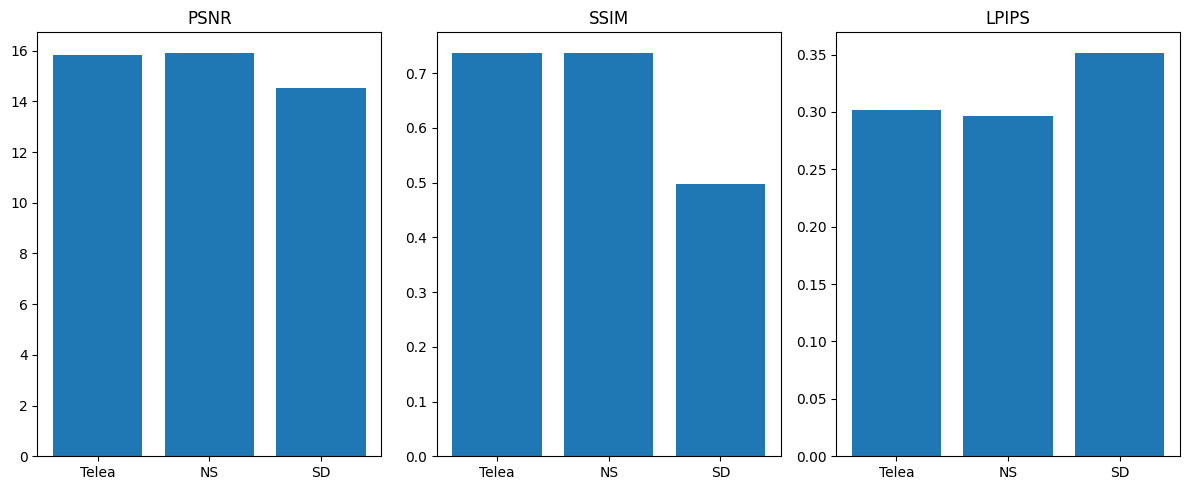

In [17]:
# ===== CELL 12: PLOTS =====

import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

# PSNR
plt.subplot(1,3,1)
plt.bar(["Telea","NS","SD"],
        [summary["telea_psnr"], summary["ns_psnr"], summary["sd_psnr"]])
plt.title("PSNR")

# SSIM
plt.subplot(1,3,2)
plt.bar(["Telea","NS","SD"],
        [summary["telea_ssim"], summary["ns_ssim"], summary["sd_ssim"]])
plt.title("SSIM")

# LPIPS
plt.subplot(1,3,3)
plt.bar(["Telea","NS","SD"],
        [summary["telea_lpips"], summary["ns_lpips"], summary["sd_lpips"]])
plt.title("LPIPS")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "comparison_plot.png"))
plt.show()

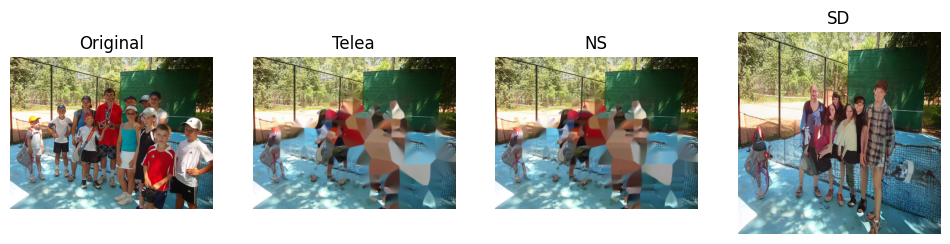

In [18]:
# ===== CELL 13: VISUAL GRID =====

idx = 0  # change index to view others

row = df.iloc[idx]

img = read_rgb(row["raw_image_path"])

sample_id = row["id"]

telea = read_rgb(os.path.join(OUT_DIR, "telea", sample_id + ".png"))
ns    = read_rgb(os.path.join(OUT_DIR, "ns", sample_id + ".png"))
sd    = read_rgb(os.path.join(OUT_DIR, "sd", sample_id + ".png"))

plt.figure(figsize=(12,6))

plt.subplot(1,4,1)
plt.title("Original")
plt.imshow(img)
plt.axis("off")

plt.subplot(1,4,2)
plt.title("Telea")
plt.imshow(telea)
plt.axis("off")

plt.subplot(1,4,3)
plt.title("NS")
plt.imshow(ns)
plt.axis("off")

plt.subplot(1,4,4)
plt.title("SD")
plt.imshow(sd)
plt.axis("off")

plt.show()